In [1]:
import pandas as pd
from time import time

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler, QuantileTransformer, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from xgboost import XGBClassifier

from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import matplotlib.pyplot as plt
from feature_engine.outliers import Winsorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score


import random
import numpy as np
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer


import joblib
from sklearn.model_selection import RandomizedSearchCV, ParameterGrid

RT = 42
RS = 42
RANDOM_STATE = 42
USE_RISK = True


---
## 0. Load Data

In [2]:
X_test = pd.read_csv("/Users/fangsiyu/Desktop/SDU-2026-fall-code/AML/kaggle/X_test.csv")
X_train = pd.read_csv("/Users/fangsiyu/Desktop/SDU-2026-fall-code/AML/kaggle/X_train.csv")
y_train = pd.read_csv("/Users/fangsiyu/Desktop/SDU-2026-fall-code/AML/kaggle/y_train.csv")


X_test['Gender'] = X_test['Gender'].map({'Female': 0, 'Male': 1})
X_train['Gender'] = X_train['Gender'].map({'Female': 0, 'Male': 1})
y_train['Diabetes'] = y_train['Diabetes'].map({'No': 0, 'Yes': 1})


X_train = X_train.set_index('ID')
X_test = X_test.set_index('ID')
y_train = y_train.set_index('ID')['Diabetes']

---
## 1. Train Test Split

In [3]:
X_t, X_val, y_t, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.1,
    random_state=RS,
    stratify=y_train
)
print(f"X_t, y_t, {len(X_t), len(y_t)} \nX_val, y_val {len(X_val), len(y_val)}")
print(f"Length of X_test {len(X_test)}")

X_t, y_t, (47717, 47717) 
X_val, y_val (5302, 5302)
Length of X_test 17673


---
## 2. EDA & Build Processor

In [4]:
for col in X_train.columns:
    print(col, X_train[col].value_counts().to_dict())

HighBP {1.0: 29816, 0.0: 23203}
HighChol {1.0: 27798, 0.0: 25221}
CholCheck {1.0: 51722, 0.0: 1297}
BMI {27.0: 4759, 26.0: 3770, 28.0: 3449, 24.0: 3258, 29.0: 3231, 30.0: 3205, 25.0: 2942, 31.0: 2817, 32.0: 2577, 23.0: 2523, 33.0: 2329, 22.0: 2103, 34.0: 1933, 21.0: 1565, 35.0: 1546, 36.0: 1353, 37.0: 1219, 38.0: 1021, 20.0: 971, 39.0: 909, 40.0: 700, 19.0: 546, 41.0: 527, 43.0: 508, 42.0: 504, 44.0: 354, 18.0: 280, 45.0: 279, 46.0: 253, 47.0: 208, 48.0: 156, 49.0: 153, 50.0: 146, 17.0: 127, 51.0: 92, 52.0: 87, 53.0: 75, 55.0: 71, 16.0: 50, 56.0: 44, 54.0: 38, 58.0: 33, 57.0: 31, 15.0: 25, 59.0: 24, 60.0: 19, 63.0: 14, 87.0: 13, 77.0: 12, 79.0: 11, 84.0: 11, 61.0: 11, 62.0: 11, 81.0: 10, 14.0: 10, 75.0: 10, 71.0: 9, 82.0: 9, 73.0: 8, 64.0: 8, 65.0: 7, 92.0: 7, 70.0: 7, 66.0: 7, 67.0: 7, 68.0: 7, 72.0: 6, 13.0: 4, 89.0: 3, 74.0: 2, 85.0: 1, 98.0: 1, 80.0: 1, 95.0: 1, 78.0: 1}
Smoker {0.0: 27933, 1.0: 25086}
Stroke {0.0: 49698, 1.0: 3321}
HeartDiseaseorAttack {0.0: 45156, 1.0: 7863}
Phys

In [5]:
for col in X_train.columns:
    print(col, X_train[col].value_counts().count())

HighBP 2
HighChol 2
CholCheck 2
BMI 75
Smoker 2
Stroke 2
HeartDiseaseorAttack 2
PhysActivity 2
Fruits 2
Veggies 2
HvyAlcoholConsump 2
AnyHealthcare 2
NoDocbcCost 2
GenHlth 5
MentHlth 31
PhysHlth 31
DiffWalk 2
Age 13
Education 6
Income 8
Gender 2


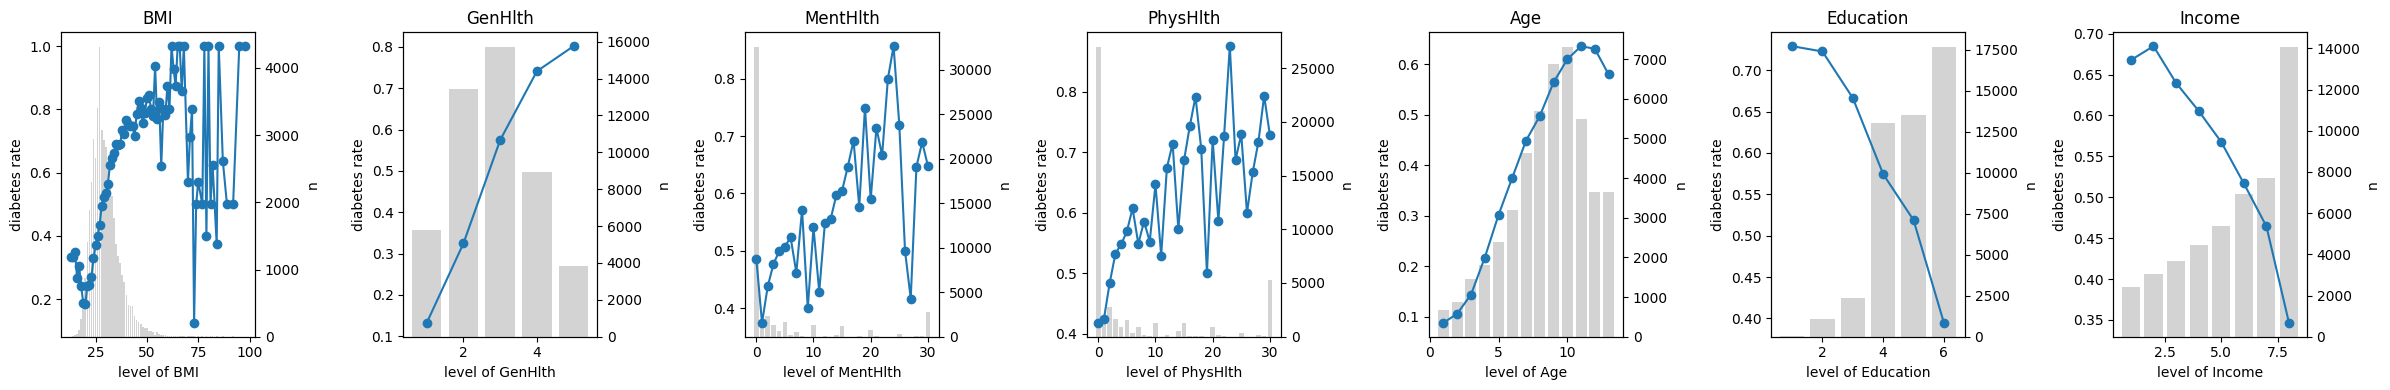

In [6]:
cols = ['BMI','GenHlth', 'MentHlth','PhysHlth','Age', 'Education', 'Income']

def make_plots(cols, df):
    fig, axes = plt.subplots(1, len(cols), figsize=(24, 4))
    for ax, col in zip(axes, cols):
        g = y_t.groupby(df[col])
        rate = g.mean()
        n = g.size()

        ax2 = ax.twinx()
        ax2.bar(n.index, n.values, color='lightgray', width=0.8)
        ax2.set_ylabel('n')

        ax.plot(rate.index, rate.values, marker='o', color='C0')
        ax.set_title(col)
        ax.set_xlabel(f"level of {col}")
        ax.set_ylabel('diabetes rate')

        ax.set_zorder(ax2.get_zorder() + 1)
        ax.patch.set_visible(False)

    plt.tight_layout()
    plt.show()

make_plots(cols, X_t)

In [ ]:
# prep = make_preprocessor().fit(X_t)
# Xt_prep = pd.DataFrame(prep.transform(X_t),
#                        columns=prep.get_feature_names_out(), index=X_t.index)

# new_cols = ['bmi__BMI', 'num__MentHlth','num__PhysHlth', 'num__Education']

# make_plots(new_cols, Xt_prep)

---
## 2.1 Baseline Model

In [7]:
lr_base = Pipeline([
    ("prep", ColumnTransformer(
        [("bmi", StandardScaler(), ["BMI"])],
        remainder=StandardScaler(),
    )),
    ("clf", LogisticRegression(solver="liblinear", C=0.1, l1_ratio=0, max_iter=5000, random_state=RS)),
])
# lr_base.set_params(prep__num=QuantileTransformer(output_distribution="normal", random_state=RT))

hgb_base = HistGradientBoostingClassifier(
    max_iter=400, max_leaf_nodes=49, min_samples_leaf=50,
    learning_rate=0.03, l2_regularization=0.3, random_state=RS,
)

---
## 2.2 inspect BMI

In [8]:
random.seed(RS)
SEEDS = random.sample(range(1, 1001), 20)


def who_bins(x):
    return np.digitize(x, [18.5, 25, 30, 35, 40])


def cv_accuracy(model, X, y, seed):
    cv_s = StratifiedKFold(5, shuffle=True, random_state=seed)
    scores = cross_val_score(clone(model), X, y, cv=cv_s, scoring="accuracy", n_jobs=-1)
    return scores.mean()


def paired_test(base, variants, X, y, seeds=SEEDS):
    rows = []
    for s in seeds:
        base_score = cv_accuracy(base, X, y, s)
        row = {"seed": s, "base": base_score}
        for name, model in variants.items():
            row[name] = cv_accuracy(model, X, y, s) - base_score
        rows.append(row)

    table = pd.DataFrame(rows).set_index("seed")
    diffs = table.drop(columns="base")
    summary = pd.DataFrame({
        "mean diff": diffs.mean(),
        "wins vs base": (diffs > 0).sum(),
    })
    return table, summary


CLIP_OPTIONS = {
    "clip right 0.5%": ("right", 0.005),
    "clip right 1%":   ("right", 0.01),
    "clip right 2%":   ("right", 0.02),
    "clip right 5%":   ("right", 0.05),
    "clip both 1%":    ("both",  0.01),
    "clip both 5%":    ("both",  0.05),
}


lr_variants = {}

for name, (tail, fold) in CLIP_OPTIONS.items():
    bmi_step = Pipeline([
        ("clip", Winsorizer(capping_method="quantiles", tail=tail, fold=fold)),
        ("scale", StandardScaler()),
    ])
    lr_variants[f"{name} + Standard"] = clone(lr_base).set_params(prep__bmi=bmi_step)

lr_variants["Quantile"] = clone(lr_base).set_params(
    prep__bmi=QuantileTransformer(output_distribution="normal", random_state=RS)
)

lr_variants["WHO bins one-hot"] = clone(lr_base).set_params(
    prep__bmi=Pipeline([
        ("bin", FunctionTransformer(who_bins)),
        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
)

lr_table, lr_summary = paired_test(lr_base, lr_variants, X_t, y_t)
print("LR: BMI handling (base = StandardScaler only)")
display(lr_table.round(4))
display(lr_summary.round(4))


hgb_variants = {}

bmi_quantile = ColumnTransformer(
    [("bmi", QuantileTransformer(output_distribution="normal", random_state=RS), ["BMI"])],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

hgb_variants["Quantile"] = Pipeline([
    ("quant", bmi_quantile),
    ("hgb", clone(hgb_base)),
])

for name, (tail, fold) in CLIP_OPTIONS.items():
    clip = Winsorizer(capping_method="quantiles", tail=tail, fold=fold, variables=["BMI"])
    hgb_variants[name] = Pipeline([
        ("clip", clip),
        ("hgb", clone(hgb_base)),
    ])

hgb_table, hgb_summary = paired_test(hgb_base, hgb_variants, X_t, y_t)
print("HGB: BMI handling (base = raw BMI)")
display(hgb_table.round(4))
display(hgb_summary.round(4))

LR: BMI handling (base = StandardScaler only)


,base,clip right 0.5% + Standard,clip right 1% + Standard,clip right 2% + Standard,clip right 5% + Standard,clip both 1% + Standard,clip both 5% + Standard,Quantile,WHO bins one-hot
seed,,,,,,,,,
655,0.7503,0.0009,0.0010,0.0018,0.0025,0.0009,0.0016,0.0038,0.0026
115,0.7511,0.0001,0.0008,0.0010,0.0014,0.0006,0.0005,0.0028,0.0017
26,0.7506,0.0006,0.0009,0.0012,0.0022,0.0008,0.0016,0.0029,0.0023
760,0.7508,0.0004,0.0007,0.0012,0.0022,0.0007,0.0013,0.0030,0.0025
282,0.7508,0.0006,0.0008,0.0012,0.0020,0.0005,0.0014,0.0029,0.0017
251,0.7511,0.0005,0.0005,0.0009,0.0019,0.0005,0.0012,0.0028,0.0019
229,0.7508,0.0005,0.0006,0.0006,0.0022,0.0004,0.0014,0.0031,0.0016
143,0.7507,0.0003,0.0008,0.0011,0.0019,0.0005,0.0012,0.0027,0.0026
755,0.7511,0.0005,0.0009,0.0007,0.0014,0.0005,0.0006,0.0027,0.0014


,mean diff,wins vs base
clip right 0.5% + Standard,0.0005,20
clip right 1% + Standard,0.0009,20
clip right 2% + Standard,0.0012,20
clip right 5% + Standard,0.0021,20
clip both 1% + Standard,0.0007,20
clip both 5% + Standard,0.0014,20
Quantile,0.0032,20
WHO bins one-hot,0.0020,20


HGB: BMI handling (base = raw BMI)


,base,Quantile,clip right 0.5%,clip right 1%,clip right 2%,clip right 5%,clip both 1%,clip both 5%
seed,,,,,,,,
655,0.7561,0.0,0.0001,0.0001,0.0003,0.0004,0.0002,-0.0005
115,0.7570,0.0,-0.0003,-0.0007,-0.0005,-0.0006,-0.0015,-0.0007
26,0.7567,0.0,0.0003,0.0005,0.0007,0.0006,0.0005,-0.0001
760,0.7568,0.0,-0.0002,-0.0000,-0.0002,-0.0003,-0.0001,-0.0000
282,0.7566,0.0,-0.0001,0.0000,0.0007,-0.0006,-0.0001,-0.0005
251,0.7550,0.0,0.0003,0.0003,-0.0001,-0.0001,0.0007,0.0007
229,0.7556,0.0,-0.0001,-0.0005,0.0001,-0.0002,0.0002,-0.0002
143,0.7555,0.0,0.0000,-0.0003,-0.0001,0.0001,0.0003,0.0001
755,0.7557,0.0,0.0004,0.0006,0.0004,0.0004,0.0001,0.0010


,mean diff,wins vs base
Quantile,0.0000,0
clip right 0.5%,0.0000,10
clip right 1%,0.0000,13
clip right 2%,0.0002,11
clip right 5%,0.0000,10
clip both 1%,0.0001,12
clip both 5%,-0.0001,7


---
## 2.3 Inspect RiskCount

In [9]:
RISK_COLS = ['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack', 'DiffWalk']


def add_features(X, risk_cols=tuple(RISK_COLS), bmi_cut=30, poor_health=False, healthy=False):
    X = X.copy()
    X["RiskCount"] = X[list(risk_cols)].sum(axis=1)
    if bmi_cut is not None:
        X["RiskCount"] += (X["BMI"] >= bmi_cut).astype(int) # the Risk 6
    if poor_health:
        X["RiskCount"] += (X["GenHlth"] >= 4).astype(int)
    if healthy:
        X["HealthyCount"] = X[["PhysActivity", "Fruits", "Veggies"]].sum(axis=1)
    return X


def with_feats(model, kw):
    return Pipeline([
        ("feat", FunctionTransformer(add_features, kw_args=kw)), # FunctionTransformer, a nice tool to wrap up py function into sklearn pipeline featable form
        ("model", clone(model)), # the 'kw_args' will unwrap the item of {} and works as a key val conpound to server the py function, see the dict() in RISK_VARIANTS
    ])


lr_new = clone(lr_base).set_params(
    prep__bmi=QuantileTransformer(output_distribution="normal", random_state=RS)
)
hgb_new = clone(hgb_base)

RISK_VARIANTS = {
    "Risk 6":                dict(),
    "Risk 5 (no BMI)":       dict(bmi_cut=None),
    "Risk 6, BMI>=25":       dict(bmi_cut=25),
    "Risk 6 + CholCheck":    dict(risk_cols=tuple(RISK_COLS) + ("CholCheck",)),
    "Risk 6 + PoorGenHlth":  dict(poor_health=True),
    "Risk 6 + HealthyCount": dict(healthy=True),
}

for name, model in {"LR": lr_new, "HGB": hgb_new}.items():
    variants = {label: with_feats(model, kw) for label, kw in RISK_VARIANTS.items()}
    table, summary = paired_test(model, variants, X_t, y_t)
    print(f"{name}: combined features (base = no combined features)")
    display(table.round(4))
    display(summary.round(4))

LR: combined features (base = no combined features)


,base,Risk 6,Risk 5 (no BMI),"Risk 6, BMI>=25",Risk 6 + CholCheck,Risk 6 + PoorGenHlth,Risk 6 + HealthyCount
seed,,,,,,,
655,0.7540,-0.0002,0.0000,-0.0002,-0.0002,-0.0000,-0.0002
115,0.7539,0.0004,-0.0000,-0.0001,0.0004,-0.0002,0.0004
26,0.7534,0.0004,0.0000,0.0000,0.0003,-0.0001,0.0004
760,0.7538,0.0005,0.0000,-0.0002,0.0005,-0.0002,0.0005
282,0.7538,0.0004,-0.0000,-0.0001,0.0004,-0.0002,0.0004
251,0.7539,0.0000,-0.0000,-0.0002,0.0000,-0.0003,0.0000
229,0.7540,-0.0001,0.0000,-0.0004,-0.0001,-0.0002,-0.0001
143,0.7535,0.0004,0.0000,-0.0000,0.0004,-0.0000,0.0004
755,0.7538,-0.0001,-0.0001,-0.0001,-0.0001,-0.0001,-0.0001


,mean diff,wins vs base
Risk 6,0.0001,12
Risk 5 (no BMI),-0.0000,6
"Risk 6, BMI>=25",-0.0001,4
Risk 6 + CholCheck,0.0001,12
Risk 6 + PoorGenHlth,-0.0001,2
Risk 6 + HealthyCount,0.0001,12


HGB: combined features (base = no combined features)


,base,Risk 6,Risk 5 (no BMI),"Risk 6, BMI>=25",Risk 6 + CholCheck,Risk 6 + PoorGenHlth,Risk 6 + HealthyCount
seed,,,,,,,
655,0.7561,0.0002,-0.0006,-0.0005,-0.0006,0.0006,0.0001
115,0.7570,-0.0004,-0.0013,-0.0004,-0.0010,-0.0005,-0.0003
26,0.7567,0.0007,-0.0001,0.0009,0.0012,0.0010,0.0005
760,0.7568,-0.0001,-0.0010,-0.0002,0.0001,-0.0001,-0.0007
282,0.7566,-0.0009,-0.0008,-0.0012,0.0005,-0.0006,-0.0008
251,0.7550,0.0012,0.0008,0.0011,0.0007,0.0006,0.0016
229,0.7556,0.0003,0.0003,0.0002,0.0000,-0.0004,-0.0001
143,0.7555,0.0004,0.0007,0.0000,0.0012,0.0012,0.0005
755,0.7557,0.0008,0.0012,0.0013,0.0007,0.0014,-0.0003


,mean diff,wins vs base
Risk 6,0.0002,13
Risk 5 (no BMI),0.0001,12
"Risk 6, BMI>=25",0.0001,10
Risk 6 + CholCheck,0.0002,11
Risk 6 + PoorGenHlth,0.0002,12
Risk 6 + HealthyCount,0.0001,11


---
## 2.4 HealthyCount

In [10]:
lr_base_t4 = with_feats(lr_new, dict(bmi_cut=25))
lr_healthy = with_feats(lr_new, dict(bmi_cut=25, healthy=True))

lr_table, lr_summary = paired_test(lr_base_t4, {"+ HealthyCount": lr_healthy}, X_t, y_t)
print("LR: add HealthyCount (base = Quantile BMI + Risk 6, BMI>=25)")
display(lr_table.round(4))
display(lr_summary.round(4))


hgb_base_t4 = with_feats(hgb_new, dict())
hgb_healthy = with_feats(hgb_new, dict(healthy=True))

hgb_table, hgb_summary = paired_test(hgb_base_t4, {"+ HealthyCount": hgb_healthy}, X_t, y_t)
print("HGB: add HealthyCount (base = raw BMI + Risk 6)")
display(hgb_table.round(4))
display(hgb_summary.round(4))

LR: add HealthyCount (base = Quantile BMI + Risk 6, BMI>=25)


,base,+ HealthyCount
seed,,
655,0.7538,0.0
115,0.7538,0.0
26,0.7535,0.0
760,0.7536,0.0
282,0.7537,-0.0
251,0.7537,0.0
229,0.7536,0.0
143,0.7535,0.0
755,0.7537,0.0


,mean diff,wins vs base
+ HealthyCount,0.0,7


HGB: add HealthyCount (base = raw BMI + Risk 6)


,base,+ HealthyCount
seed,,
655,0.7564,-0.0001
115,0.7566,0.0001
26,0.7574,-0.0002
760,0.7566,-0.0005
282,0.7557,0.0000
251,0.7562,0.0003
229,0.7560,-0.0005
143,0.7559,0.0001
755,0.7565,-0.0010


,mean diff,wins vs base
+ HealthyCount,-0.0001,8


---
## 2.5 One-Hot or Numeric

In [11]:
def lr_step4(onehot_cols):
    blocks = [
        ("bmi", QuantileTransformer(output_distribution="normal", random_state=RS), 
         ["BMI"])
         ]
    if onehot_cols:
        blocks.append(("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False), onehot_cols))
    return Pipeline([
        ("feat", FunctionTransformer(add_features, kw_args=dict(bmi_cut=25))),
        ("prep", ColumnTransformer(blocks, remainder=StandardScaler())),
        ("clf", LogisticRegression(solver="liblinear", C=0.1, l1_ratio=0, max_iter=5000, random_state=RS)),
    ])


lr_step3 = lr_step4([])

t5_variants = {
    "one-hot GenHlth": lr_step4(["GenHlth"]),
    "one-hot Age": lr_step4(["Age"]),
    "one-hot GenHlth + Age": lr_step4(["GenHlth", "Age"]),
    "one-hot all 4 ordinal": lr_step4(["GenHlth", "Age", "Education", "Income"]),
}

t5_table, t5_summary = paired_test(lr_step3, t5_variants, X_t, y_t)
print("Step 4 - LR: one-hot vs numeric (base = all numeric, Quantile BMI + Risk 6 with BMI>=25)")
display(t5_table.round(4))
display(t5_summary.round(4))

Step 4 - LR: one-hot vs numeric (base = all numeric, Quantile BMI + Risk 6 with BMI>=25)


,base,one-hot GenHlth,one-hot Age,one-hot GenHlth + Age,one-hot all 4 ordinal
seed,,,,,
655,0.7538,-0.0005,-0.0001,-0.0001,0.0003
115,0.7538,-0.0004,-0.0001,-0.0000,0.0001
26,0.7535,-0.0004,-0.0001,0.0004,0.0005
760,0.7536,0.0001,0.0001,0.0002,0.0008
282,0.7537,0.0000,0.0002,0.0003,0.0006
251,0.7537,-0.0002,-0.0001,-0.0001,0.0001
229,0.7536,-0.0005,-0.0000,-0.0003,-0.0003
143,0.7535,0.0002,-0.0000,-0.0005,-0.0004
755,0.7537,0.0001,-0.0005,-0.0000,0.0000


,mean diff,wins vs base
one-hot GenHlth,-0.0003,6
one-hot Age,-0.0002,6
one-hot GenHlth + Age,-0.0002,4
one-hot all 4 ordinal,0.0001,13


In [ ]:
# Step              LR                                          Tree (HGB)
# BMI               QuantileTransformer (normal)                Raw value, no transform
# RiskCount         Risk 6, BMI cut at 25 (not 30)              Risk 6
# HealthyCount      Not added                                   Not added
# Ordinal columns   One-hot: GenHlth, Age, Education, Income    Numeric (raw)
#
# Risk 6 = HighBP + HighChol + Stroke + HeartDiseaseorAttack + DiffWalk + (BMI >= cut)

In [12]:
BINARY_COLS = [
    'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack',
    'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare',
    'NoDocbcCost', 'DiffWalk', 'Gender',
]
NUMERIC_COLS = ['MentHlth', 'PhysHlth','Education']
ONEHOT_COLS = ['GenHlth', 'Age', 'Income']

RISK_COLS = ['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack', 'DiffWalk']

SCALER_OPTIONS = [
    StandardScaler(),
    MinMaxScaler(),
    QuantileTransformer(output_distribution="normal", random_state=RT),
]


def add_risk(X, bmi_cut=30):
    if not USE_RISK:
        return X
    X = X.copy()
    X['RiskCount'] = X[RISK_COLS].sum(axis=1) + (X['BMI'] >= bmi_cut).astype(int)
    return X


def num_cols(X):
    return [c for c in NUMERIC_COLS + ['RiskCount'] if c in X.columns]


def make_preprocessor():
    return ColumnTransformer(
        [
            ("bmi", QuantileTransformer(output_distribution="normal", random_state=RT), ['BMI']),
            ("num", StandardScaler(), num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ONEHOT_COLS),
        ],
        remainder=StandardScaler(),
    )

---
## 3. Grid

In [14]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.kernel_approximation import Nystroem

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

def linear_model(*steps):
    return Pipeline([
        ("risk", FunctionTransformer(add_risk, kw_args={"bmi_cut": 25})),
        ("prep", make_preprocessor()),
        *steps,
    ])

def tree_model(model):
    return Pipeline([
        ("risk", FunctionTransformer(add_risk)),
        ("clf", model),
    ])


search_space = {
    "Logistic Regression": (
        linear_model(("clf", LogisticRegression(solver="liblinear", max_iter=5000, random_state=RT))),
        {"prep__num": SCALER_OPTIONS,
         "clf__l1_ratio": [0, 1],
         "clf__C": [0.01, 0.03, 0.1, 0.3, 1]},
    ),
    "LR + Interactions": (
        linear_model(("poly", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
                     ("clf", LogisticRegression(max_iter=5000, random_state=RT))),
        {"prep__num": [StandardScaler()],
         "clf__C": [0.003, 0.01, 0.03, 0.1]},
    ),
    "LDA": (
        linear_model(("clf", LinearDiscriminantAnalysis(solver="lsqr"))),
        {"prep__num": SCALER_OPTIONS,
         "clf__shrinkage": [None, "auto"]},
    ),
    "Kernel SVM (Nystroem)": (
        linear_model(("kernel", Nystroem(kernel="rbf", random_state=RT)),
                     ("clf", LogisticRegression(max_iter=5000, random_state=RT))),
        {"prep__num": [StandardScaler()],
         "kernel__n_components": [500, 1000],
         "kernel__gamma": [0.02, 0.05, 0.1],
         "clf__C": [0.3, 1, 3]},
    ),
    "KNN": (
        linear_model(("clf", KNeighborsClassifier())),
        {"prep__num": SCALER_OPTIONS,
         "clf__n_neighbors": [50, 75, 100, 150],
         "clf__p": [1, 2],
         "clf__weights": ["uniform", "distance"]},
    ),

    "Decision Tree": (
        tree_model(DecisionTreeClassifier(random_state=RT)),
        {"clf__criterion": ["gini", "entropy"],
         "clf__max_depth": [4, 6, 8, 10, 12],
         "clf__min_samples_leaf": [10, 20, 50, 100]},
    ),
    "Random Forest": (
        tree_model(RandomForestClassifier(n_estimators=500, random_state=RT, n_jobs=1)),
        {"clf__max_depth": [10, 15, 20, None],
         "clf__min_samples_leaf": [1, 5, 10, 20],
         "clf__max_features": ["sqrt", 0.3, 0.5]},
    ),
    "Extra Trees": (
        tree_model(ExtraTreesClassifier(n_estimators=500, random_state=RT, n_jobs=1)),
        {"clf__max_depth": [10, 15, 20, None],
         "clf__min_samples_leaf": [5, 10, 20],
         "clf__max_features": ["sqrt", 0.5, 0.8]},
    ),
    "AdaBoost": (
        tree_model(AdaBoostClassifier(estimator=DecisionTreeClassifier(), random_state=RT)),
        {"clf__estimator__max_depth": [1, 2, 3],
         "clf__n_estimators": [400, 800],
         "clf__learning_rate": [0.5, 1.0]},
    ),
    "Gradient Boosting": (
        tree_model(GradientBoostingClassifier(random_state=RT)),
        {"clf__learning_rate": [0.06, 0.03, 0.1, 0.16],
         "clf__n_estimators": [200, 400, 600],
         "clf__max_depth": [1, 2, 3, 4],
         "clf__min_samples_leaf": [20, 50, 100, 150, 200],
         "clf__subsample": [0.7, 0.8, 0.9, 1]},
    ),
    "HistGradientBoosting": (
        tree_model(HistGradientBoostingClassifier(random_state=RT)),
        {"clf__learning_rate": [0.03, 0.05, 0.1, 0.06, 0.1, 0.16],
         "clf__max_iter": [100, 150, 200, 400],
         "clf__max_leaf_nodes": [9,7, 15, 20, 30],
         "clf__min_samples_leaf": [20, 50, 100, 200],
         "clf__l2_regularization": [0,0.3, 0.5, 0.7, 1]},
    ),

    "XGBoost": (
        tree_model(XGBClassifier(random_state=RT, n_jobs=1, eval_metric="logloss")),
        {"clf__n_estimators": [300, 600],
         "clf__learning_rate": [0.03, 0.1],
         "clf__max_depth": [4, 6, 8],
         "clf__colsample_bytree": [0.6, 0.8, 1.0],
         "clf__min_child_weight": [1, 5]},
    ),
    "LightGBM": (
        tree_model(LGBMClassifier(subsample_freq=1, random_state=RT, n_jobs=1, verbose=-1)),
        {"clf__n_estimators": [300, 600],
         "clf__learning_rate": [0.03, 0.1],
         "clf__num_leaves": [7, 15, 31],
         "clf__colsample_bytree": [0.6, 0.8],
         "clf__subsample": [0.7, 1.0],
         "clf__reg_lambda": [0, 1]},
    ),
    "CatBoost": (
        tree_model(CatBoostClassifier(random_seed=RT, verbose=0, thread_count=1)),
        {"clf__depth": [4, 6, 8],
         "clf__iterations": [600, 1000],
         "clf__l2_leaf_reg": [3, 10],
         "clf__learning_rate": [0.03, 0.1]},
    ),

    "Dummy": (
        tree_model(DummyClassifier(strategy="most_frequent")),
        {},
    ),
}

In [15]:

N_ITER = 120

rows, grid_models, searches = [], {}, {}

for name, (model, grid) in search_space.items():
    t0 = time()
    n_combos = len(ParameterGrid(grid))
    common = dict(cv=cv, scoring="accuracy", n_jobs=-1)
    if n_combos > N_ITER:
        search = RandomizedSearchCV(model, grid, n_iter=N_ITER, random_state=RS, **common)
    else:
        search = GridSearchCV(model, grid, **common)
    search.fit(X_t, y_t)

    searches[name] = search
    grid_models[name] = search.best_estimator_
    bp = search.best_params_

    rows.append({
        "Model": name,
        "Scaler": type(bp["prep__num"]).__name__ if "prep__num" in bp else "-",
        "Tried": f"{min(n_combos, N_ITER)}/{n_combos}",
        "CV Acc": search.best_score_,
        "CV Acc std": search.cv_results_["std_test_score"][search.best_index_],
        "Val Acc": accuracy_score(y_val, search.predict(X_val)),
        "Time (s)": round(time() - t0),
        "Best params": {k.split("__")[-1]: v for k, v in bp.items() if k != "prep__num"},
    })
    print(f"{name} done, {rows[-1]['Time (s)']} sec")

grid_results = (pd.DataFrame(rows)
                .sort_values("CV Acc", ascending=False)
                .reset_index(drop=True))

# joblib.dump({"grid_models": grid_models, "grid_results": grid_results}, "grid.joblib")

display(grid_results.drop(columns="Best params").round(4))
for _, r in grid_results.iterrows():
    print(f"{r['Model']}: {r['Best params']}")

Logistic Regression done, 8 sec


/Users/fangsiyu/dev-env/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


LR + Interactions done, 16 sec
LDA done, 2 sec


/Users/fangsiyu/dev-env/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Kernel SVM (Nystroem) done, 40 sec
KNN done, 112 sec
Decision Tree done, 2 sec


...

Random Forest done, 341 sec


/Users/fangsiyu/dev-env/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Extra Trees done, 330 sec
AdaBoost done, 95 sec
Gradient Boosting done, 466 sec
HistGradientBoosting done, 53 sec
XGBoost done, 34 sec
LightGBM done, 56 sec
CatBoost done, 97 sec
Dummy done, 0 sec


,Model,Scaler,Tried,CV Acc,CV Acc std,Val Acc,Time (s)
0,Gradient Boosting,-,120/960,0.7580,0.0040,0.7597,466
1,LightGBM,-,96/96,0.7575,0.0037,0.7620,56
2,HistGradientBoosting,-,120/2400,0.7575,0.0037,0.7582,53
3,XGBoost,-,72/72,0.7575,0.0042,0.7624,34
4,CatBoost,-,24/24,0.7569,0.0036,0.7639,97
5,Random Forest,-,48/48,0.7550,0.0047,0.7529,341
6,Kernel SVM (Nystroem),StandardScaler,18/18,0.7549,0.0035,0.7550,40
7,AdaBoost,-,12/12,0.7545,0.0031,0.7556,95
8,Logistic Regression,MinMaxScaler,30/30,0.7540,0.0034,0.7556,8
9,LR + Interactions,StandardScaler,4/4,0.7540,0.0043,0.7580,16


Gradient Boosting: {'subsample': 0.8, 'n_estimators': 600, 'min_samples_leaf': 150, 'max_depth': 3, 'learning_rate': 0.06}
LightGBM: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'n_estimators': 600, 'num_leaves': 15, 'reg_lambda': 0, 'subsample': 0.7}
HistGradientBoosting: {'min_samples_leaf': 100, 'max_leaf_nodes': 30, 'max_iter': 400, 'learning_rate': 0.1, 'l2_regularization': 0.5}
XGBoost: {'colsample_bytree': 0.6, 'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 300}
CatBoost: {'depth': 6, 'iterations': 1000, 'l2_leaf_reg': 3, 'learning_rate': 0.03}
Random Forest: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}
Kernel SVM (Nystroem): {'C': 1, 'gamma': 0.02, 'n_components': 1000}
AdaBoost: {'max_depth': 3, 'learning_rate': 1.0, 'n_estimators': 800}
Logistic Regression: {'C': 0.1, 'l1_ratio': 0}
LR + Interactions: {'C': 0.003}
LDA: {'shrinkage': 'auto'}
Extra Trees: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 20}
De

---
## Further Turning

In [ ]:
import joblib
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, ParameterGrid

N_ITER_FINE = 120

fine_space = {
    "Gradient Boosting": {
        "clf__learning_rate": [0.06, 0.1, 0.16],
        "clf__max_depth": [2, 3, 4],
        "clf__min_samples_leaf": [50, 100, 200],
        "clf__n_estimators": [300, 400, 600],
        "clf__subsample": [0.7, 0.8, 0.9],
    },
    # "XGBoost": {
    #     "clf__colsample_bytree": [0.5, 0.6, 0.7],
    #     "clf__learning_rate": [0.018, 0.03, 0.048],
    #     "clf__max_depth": [5, 6, 7],
    #     "clf__min_child_weight": [1, 2],
    #     "clf__n_estimators": [225, 300, 450],
    # },
    # "CatBoost": {
    #     "clf__depth": [5, 6, 7],
    #     "clf__iterations": [450, 600, 900],
    #     "clf__l2_leaf_reg": [3, 10, 30],
    #     "clf__learning_rate": [0.018, 0.03, 0.048],
    # },
    "HistGradientBoosting": {
        "clf__learning_rate": [0.06, 0.1, 0.16],
        "clf__max_iter": [150, 200, 300],
        "clf__max_leaf_nodes": [9, 15, 24],
        "clf__min_samples_leaf": [50, 100, 200],
        "clf__l2_regularization": [0, 0.3, 1],
    },
    # "LightGBM": {
    #     "clf__colsample_bytree": [0.5, 0.6, 0.7],
    #     "clf__learning_rate": [0.018, 0.03, 0.048],
    #     "clf__n_estimators": [450, 600, 900],
    #     "clf__num_leaves": [4, 7, 11],
    #     "clf__reg_lambda": [0.3, 1, 3],
    #     "clf__subsample": [0.6, 0.7, 0.8],
    # },
}

tuning_rows, tuning_models, tuning_searches = [], {}, {}

for name, grid in fine_space.items():
    t0 = time()
    model = clone(searches[name].estimator)
    n_combos = len(ParameterGrid(grid))
    common = dict(cv=cv, scoring="accuracy", n_jobs=-1)
    if n_combos > N_ITER_FINE:
        search = RandomizedSearchCV(model, grid, n_iter=N_ITER_FINE, random_state=RT, **common)
    else:
        search = GridSearchCV(model, grid, **common)
    search.fit(X_t, y_t)

    tuning_searches[name] = search
    tuning_models[name] = search.best_estimator_

    tuning_rows.append({
        "Model": name,
        "Tried": f"{min(n_combos, N_ITER_FINE)}/{n_combos}",
        "Round1 CV Acc": searches[name].best_score_,
        "CV Acc": search.best_score_,
        "CV Acc std": search.cv_results_["std_test_score"][search.best_index_],
        "Time (s)": round(time() - t0),
        "Best params": {k.split("__")[-1]: v for k, v in search.best_params_.items()},
    })
    print(f"{name} done, {tuning_rows[-1]['Time (s)']} sec")

tuning_results = (pd.DataFrame(tuning_rows)
                  .sort_values("CV Acc", ascending=False)
                  .reset_index(drop=True))

# joblib.dump({"tuning_models": tuning_models, "tuning_results": tuning_results}, "tuning.joblib")

display(tuning_results.drop(columns="Best params").round(4))
for _, r in tuning_results.iterrows():
    print(f"{r['Model']}: {r['Best params']}")

---
## thresholds testing


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
import numpy as np
# proba_oof = cross_val_predict(clone(tuning_models["LightGBM"]), 
proba_oof = cross_val_predict(clone(grid_models["Gradient Boosting"]), 

                              X_t, y_t,
                              cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

thr = np.arange(0.30, 0.71, 0.02)
thr_table = pd.DataFrame({
    "thresholds": thr,
    "Accuracy": [accuracy_score(y_t, proba_oof >= t) for t in thr],
    "F1": [f1_score(y_t, proba_oof >= t) for t in thr],
})
thr_table.round(4)

,門檻,Accuracy,F1
0,0.30,0.7312,0.7741
1,0.32,0.7367,0.7759
2,0.34,0.7411,0.7769
3,0.36,0.7449,0.7775
4,0.38,0.7479,0.7772
5,0.40,0.7507,0.7769
6,0.42,0.7529,0.7758
7,0.44,0.7542,0.7738
8,0.46,0.7561,0.7724
9,0.48,0.7568,0.7695


---
## Ensemble

In [ ]:
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier, StackingClassifier

estimators = [
    ("XGBoost", clone(tuning_models["XGBoost"])),
    ("CatBoost", clone(tuning_models["CatBoost"])),
    # ("Gradient Boosting", clone(tuning_models["Gradient Boosting"])),
    # ("HistGradientBoosting", clone(tuning_models["HistGradientBoosting"])),
    ("lr_int", clone(grid_models["LR + Interactions"])),
    ("ksvm", clone(grid_models["Kernel SVM (Nystroem)"])),
]

ensembles = {
    "Soft Voting": VotingClassifier(estimators, voting="soft"),
    "Stacking": StackingClassifier(estimators, final_estimator=LogisticRegression(max_iter=1000), cv=5),
}

for name, model in ensembles.items():
    t0 = time()
    scores = cross_val_score(model, X_t, y_t, cv=cv, scoring="accuracy", n_jobs=-1)
    print(f"{name}: CV {scores.mean():.4f} ± {scores.std():.4f}  ({time() - t0:.0f}s)")

print(f"XGBoost ori: CV {tuning_searches['XGBoost'].best_score_:.4f}")

---
## Dump Results to CSV

In [ ]:
# from sklearn.base import clone

# final_models = {
#     "Gradient Boosting": clone(grid_models["Gradient Boosting"]),
#     "HistGradientBoosting": clone(grid_models["HistGradientBoosting"]),
#     # "XGBoost_CatBoost_lr_int_ksvm": clone(ensembles["Stacking"]),
# }

# for name, model in final_models.items():
#     model.fit(X_train, y_train)
#     y_pred_test = model.predict(X_test)

#     submission = pd.DataFrame({"ID": X_test.index, "Diabetes": y_pred_test})
#     submission['Diabetes'] = submission['Diabetes'].map({0: 'No', 1: 'Yes'})
#     submission.to_csv(f"submission_v16_{name}.csv", index=False)

#     print(name, submission['Diabetes'].value_counts().to_dict())

Gradient Boosting {'Yes': 9694, 'No': 7979}
HistGradientBoosting {'Yes': 9657, 'No': 8016}


---
## Storage HP / Roll Back

In [ ]:
# joblib.dump({"grid_models": grid_models, "grid_results": grid_results}, "grid.joblib")
# joblib.dump({"tuning_models": tuning_models, "tuning_results": tuning_results}, "tuning.joblib")

In [ ]:
# grid = joblib.load("grid.joblib")
# grid_models, grid_results = grid["grid_models"], grid["grid_results"]

# tuning = joblib.load("tuning.joblib")
# tuning_models, tuning_results = tuning["tuning_models"], tuning["tuning_results"]